# SVM, Decision Tree, Random Forest e Gradient Boosting em 6 datasets

Para cada um dos 6 datasets, este notebook:

1. separa os dados em **treino (80%)** e **teste (20%)**;
2. treina os **4 classificadores** com um único laço `for`, escolhendo os hiperparâmetros com **validação cruzada** (5 folds);
3. mede **acurácia, precisão, F1, ROC AUC** e mostra a **matriz de confusão** e a **curva ROC**;
4. compara treino e validação para ver se há **alta variância (overfitting)** ou **alto viés (underfitting)** e, com isso, justifica a escolha entre **Random Forest** e **Gradient Boosting**.

Para rodar no Colab: *Ambiente de execução → Executar tudo* (leva uns 10 minutos).

## 1. Importação das bibliotecas

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Divisão, validação cruzada e busca de hiperparâmetros
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV

# Métricas
from sklearn.metrics import (accuracy_score, precision_score, f1_score, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)
from sklearn.preprocessing import label_binarize

# Pré-processamento e pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Os 4 classificadores
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

os.makedirs("resultados/figuras", exist_ok=True)  # pasta onde as tabelas e os gráficos são salvos

## 2. Carregamento dos 6 datasets

Os arquivos são baixados direto do Kaggle (sem precisar de login) e do GitHub.
Se algum download falhar, baixe o CSV pelo site, envie para o Colab (ícone de pasta → *Fazer upload*)
e troque a URL pelo nome do arquivo, por exemplo `"heart.csv"`.

In [2]:
KAGGLE = "https://www.kaggle.com/api/v1/datasets/download/"
GITHUB = "https://raw.githubusercontent.com/"

urls = {
    "Câncer de Mama":      KAGGLE + "ahmedesso/brest-cancer/data.csv",
    "Eleições":            GITHUB + "Gabriel-SZ-Silva/LiteraryDigestElections/main/dataset_literary_digest_consolidado_1924_1936.csv",
    "Fishmorph":           KAGGLE + "menegidio/fishmorph-dataset/FISHMORPH_Order_Dataset.csv",
    "Cardiopatia":         KAGGLE + "fedesoriano/heart-failure-prediction/heart.csv",
    "Estresse Estudantil": KAGGLE + "rxnach/student-stress-factors-a-comprehensive-analysis/StressLevelDataset.csv",
    "Ultimate Pokémon":    KAGGLE + "darkmatternet/ultimate-pokmon-dataset-2025/pokemon_complete_2025.csv",
}

In [3]:
def carregar_dataset(nome, df):
    """Limpa o dataset e devolve X (atributos) e y (alvo)."""

    if nome == "Câncer de Mama":
        # M = maligno, B = benigno. 'id' é só um identificador e 'Unnamed: 32' é uma coluna vazia.
        y = df["diagnosis"]
        X = df.drop(columns=["diagnosis", "id", "Unnamed: 32"])

    elif nome == "Eleições":
        # Alvo: o republicano venceu de fato no estado? (1 = sim). Linhas sem resultado real saem.
        df = df.dropna(subset=["pct_real_rep", "pct_real_dem"])
        y = (df["pct_real_rep"] > df["pct_real_dem"]).astype(int)
        # Saem o resultado real (o alvo vem dele) e também ano e candidatos, que sozinhos já indicam o vencedor.
        X = df.drop(columns=["votos_real_rep", "votos_real_dem", "total_real", "pct_real_rep", "pct_real_dem",
                             "vies_republicano_pp", "ano", "candidato_rep", "candidato_dem"])

    elif nome == "Fishmorph":
        # Ordens com menos de 10 espécies (algumas têm 1 só) são removidas: não dá para dividir em treino,
        # teste e 5 folds de validação com tão poucos exemplos.
        contagem = df["Order"].value_counts()
        df = df[df["Order"].isin(contagem[contagem >= 10].index)]
        y = df["Order"]
        X = df.drop(columns=["Order"])

    elif nome == "Cardiopatia":
        # Colesterol e pressão iguais a 0 significam "não medido": viram valor ausente (NaN).
        df = df.copy()
        df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)
        df["RestingBP"] = df["RestingBP"].replace(0, np.nan)
        y = df["HeartDisease"]
        X = df.drop(columns=["HeartDisease"])

    elif nome == "Estresse Estudantil":
        # 0 = baixo, 1 = médio, 2 = alto
        y = df["stress_level"]
        X = df.drop(columns=["stress_level"])

    elif nome == "Ultimate Pokémon":
        # Prevê o tipo primário usando só atributos numéricos (nome, descrição e habilidades entregariam o tipo).
        y = df["type_1"]
        X = df[["num_types", "hp", "attack", "defense", "sp_attack", "sp_defense", "speed", "base_stat_total",
                "height_m", "weight_kg", "base_experience", "capture_rate", "base_happiness", "hatch_counter",
                "gender_rate", "bmi", "attack_defense_ratio", "physical_total", "special_total",
                "offensive_total", "defensive_total"]]

    return X, y


datasets = {}
for nome, url in urls.items():
    df = pd.read_csv(url)
    X, y = carregar_dataset(nome, df)
    datasets[nome] = (X, y)
    print(f"{nome}: {X.shape[0]} linhas, {X.shape[1]} atributos, {y.nunique()} classes")

Câncer de Mama: 569 linhas, 30 atributos, 2 classes
Eleições: 145 linhas, 6 atributos, 2 classes
Fishmorph: 8304 linhas, 10 atributos, 23 classes
Cardiopatia: 918 linhas, 11 atributos, 2 classes
Estresse Estudantil: 1100 linhas, 20 atributos, 3 classes
Ultimate Pokémon: 1025 linhas, 21 atributos, 18 classes


## 3. Pré-processamento e os 4 classificadores

O pré-processamento fica dentro do `Pipeline`, então ele é ajustado só com os dados de treino de cada fold
(sem vazamento de dados): números recebem imputação pela mediana e padronização; textos recebem imputação
pela moda e one-hot.

Os 4 classificadores ficam num **dicionário**: nome → (modelo, hiperparâmetros a testar).

In [4]:
preprocessador = ColumnTransformer([
    ("num", Pipeline([("imputacao", SimpleImputer(strategy="median")),
                      ("escala", StandardScaler())]),
     make_column_selector(dtype_include=np.number)),
    ("cat", Pipeline([("imputacao", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
     make_column_selector(dtype_exclude=np.number)),
])

modelos = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {"modelo__max_depth": [3, 5, 10, 20, None],
         "modelo__min_samples_split": [2, 5, 10],
         "modelo__min_samples_leaf": [1, 2, 5]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {"modelo__n_estimators": [100, 200],
         "modelo__max_depth": [5, 10, 20, None],
         "modelo__min_samples_leaf": [1, 2, 5]},
    ),
    # HistGradientBoosting é o Gradient Boosting do scikit-learn na versão rápida (o GradientBoostingClassifier
    # comum levaria mais de 20 minutos só no Fishmorph, que tem 23 classes).
    # A regularização L2 evita que ele "exploda" em classes com poucos exemplos: sem ela, o F1 no Fishmorph caía
    # de cerca de 0,70 para 0,16.
    "Gradient Boosting": (
        HistGradientBoostingClassifier(l2_regularization=1.0, random_state=42),
        {"modelo__max_iter": [100, 200],
         "modelo__learning_rate": [0.05, 0.1, 0.2],
         "modelo__max_depth": [3, 5, None]},
    ),
    "SVM": (
        SVC(random_state=42),
        {"modelo__C": [0.1, 1, 10, 100],
         "modelo__gamma": ["scale", 0.01, 0.1]},
    ),
}

## 4. Treino, validação cruzada e métricas

Para cada dataset: divisão treino/teste estratificada e validação cruzada estratificada de 5 folds.
Para cada modelo: o `RandomizedSearchCV` testa 10 combinações de hiperparâmetros com validação cruzada,
escolhe a de maior **F1** e guarda também o F1 no treino (usado na análise de viés e variância).
Depois o melhor modelo é avaliado no teste.

Precisão e F1 usam a média **macro** (todas as classes pesam igual), porque alguns datasets têm classes
com poucos exemplos. Nos datasets com mais de 2 classes, a ROC AUC é a média "um contra todos".

In [5]:
def calcular_auc(y_test, probabilidades, classes):
    if len(classes) == 2:
        return roc_auc_score(y_test == classes[1], probabilidades[:, 1])
    return roc_auc_score(y_test, probabilidades, multi_class="ovr", average="macro", labels=classes)


resultados = []   # uma linha por (dataset, modelo) com todas as métricas
previsoes = {}    # guarda as previsões de teste para os gráficos

for nome_ds, (X, y) in datasets.items():
    print(f"\n=== {nome_ds} ===")
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for nome_modelo, (modelo, parametros) in modelos.items():
        pipeline = Pipeline([("prep", preprocessador), ("modelo", modelo)])
        busca = RandomizedSearchCV(pipeline, parametros, n_iter=10, cv=cv, scoring="f1_macro",
                                   return_train_score=True, n_jobs=-1, random_state=42)
        busca.fit(X_train, y_train)
        melhor = busca.best_estimator_

        # O SVC só calcula probabilidades (necessárias para a ROC) com probability=True;
        # ligamos isso só no modelo final, para a busca não ficar lenta.
        if nome_modelo == "SVM":
            melhor.set_params(modelo__probability=True)
            melhor.fit(X_train, y_train)

        y_pred = melhor.predict(X_test)
        probabilidades = melhor.predict_proba(X_test)
        classes = melhor.classes_

        resultados.append({
            "Dataset": nome_ds,
            "Modelo": nome_modelo,
            "Acurácia": accuracy_score(y_test, y_pred),
            "Precisão": precision_score(y_test, y_pred, average="macro", zero_division=0),
            "F1": f1_score(y_test, y_pred, average="macro"),
            "ROC AUC": calcular_auc(y_test, probabilidades, classes),
            "F1 treino (CV)": busca.cv_results_["mean_train_score"][busca.best_index_],
            "F1 validação (CV)": busca.best_score_,
        })
        previsoes[(nome_ds, nome_modelo)] = (y_test, y_pred, probabilidades, classes)
        print(f"{nome_modelo:<18} F1 validação = {busca.best_score_:.3f} | F1 teste = {resultados[-1]['F1']:.3f}")

tabela = pd.DataFrame(resultados)
tabela.to_csv("resultados/metricas.csv", index=False)


=== Câncer de Mama ===
Decision Tree      F1 validação = 0.924 | F1 teste = 0.903
Random Forest      F1 validação = 0.965 | F1 teste = 0.971
Gradient Boosting  F1 validação = 0.964 | F1 teste = 0.952
SVM                F1 validação = 0.974 | F1 teste = 0.981

=== Eleições ===
Decision Tree      F1 validação = 0.842 | F1 teste = 0.688
Random Forest      F1 validação = 0.803 | F1 teste = 0.757
Gradient Boosting  F1 validação = 0.797 | F1 teste = 0.721
SVM                F1 validação = 0.804 | F1 teste = 0.824

=== Fishmorph ===
Decision Tree      F1 validação = 0.426 | F1 teste = 0.460
Random Forest      F1 validação = 0.583 | F1 teste = 0.636
Gradient Boosting  F1 validação = 0.633 | F1 teste = 0.695
SVM                F1 validação = 0.658 | F1 teste = 0.694

=== Cardiopatia ===
Decision Tree      F1 validação = 0.828 | F1 teste = 0.820
Random Forest      F1 validação = 0.853 | F1 teste = 0.890
Gradient Boosting  F1 validação = 0.862 | F1 teste = 0.873
SVM                F1 validação =

## 5. Tabelas comparativas (conjunto de teste)
Em destaque, o melhor modelo de cada dataset.

In [6]:
for metrica in ["Acurácia", "Precisão", "F1", "ROC AUC"]:
    print(f"\n{metrica} no teste")
    comparativo = tabela.pivot(index="Dataset", columns="Modelo", values=metrica)
    comparativo = comparativo.reindex(index=list(datasets), columns=list(modelos))
    display(comparativo.style.format("{:.3f}").highlight_max(axis=1, color="lightgreen"))


Acurácia no teste


Modelo,Decision Tree,Random Forest,Gradient Boosting,SVM
Dataset,,,,
Câncer de Mama,0.912,0.974,0.956,0.982
Eleições,0.690,0.759,0.724,0.828
Fishmorph,0.630,0.792,0.795,0.801
Cardiopatia,0.821,0.891,0.875,0.875
Estresse Estudantil,0.873,0.886,0.868,0.886
Ultimate Pokémon,0.220,0.263,0.302,0.332



Precisão no teste


Modelo,Decision Tree,Random Forest,Gradient Boosting,SVM
Dataset,,,,
Câncer de Mama,0.921,0.980,0.961,0.986
Eleições,0.715,0.757,0.721,0.828
Fishmorph,0.486,0.813,0.763,0.737
Cardiopatia,0.820,0.891,0.874,0.878
Estresse Estudantil,0.885,0.889,0.870,0.913
Ultimate Pokémon,0.180,0.189,0.270,0.267



F1 no teste


Modelo,Decision Tree,Random Forest,Gradient Boosting,SVM
Dataset,,,,
Câncer de Mama,0.903,0.971,0.952,0.981
Eleições,0.688,0.757,0.721,0.824
Fishmorph,0.460,0.636,0.695,0.694
Cardiopatia,0.820,0.890,0.873,0.872
Estresse Estudantil,0.875,0.887,0.868,0.888
Ultimate Pokémon,0.182,0.194,0.250,0.266



ROC AUC no teste


Modelo,Decision Tree,Random Forest,Gradient Boosting,SVM
Dataset,,,,
Câncer de Mama,0.919,0.995,0.994,0.996
Eleições,0.815,0.827,0.856,0.851
Fishmorph,0.754,0.977,0.979,0.982
Cardiopatia,0.889,0.932,0.916,0.942
Estresse Estudantil,0.964,0.985,0.983,0.982
Ultimate Pokémon,0.624,0.759,0.762,0.768


## 6. Matrizes de confusão

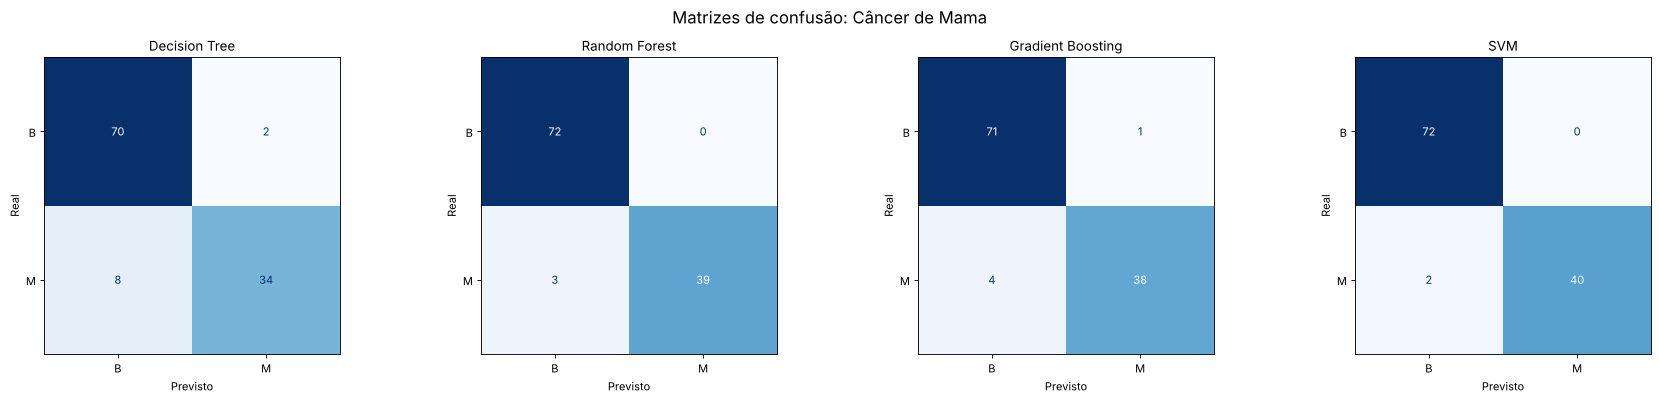

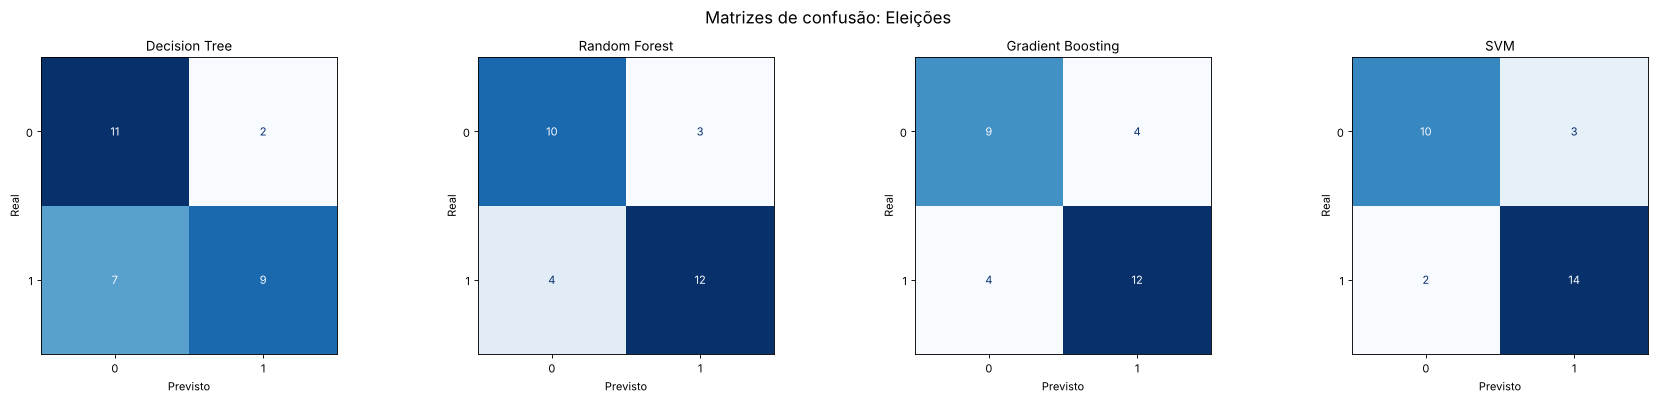

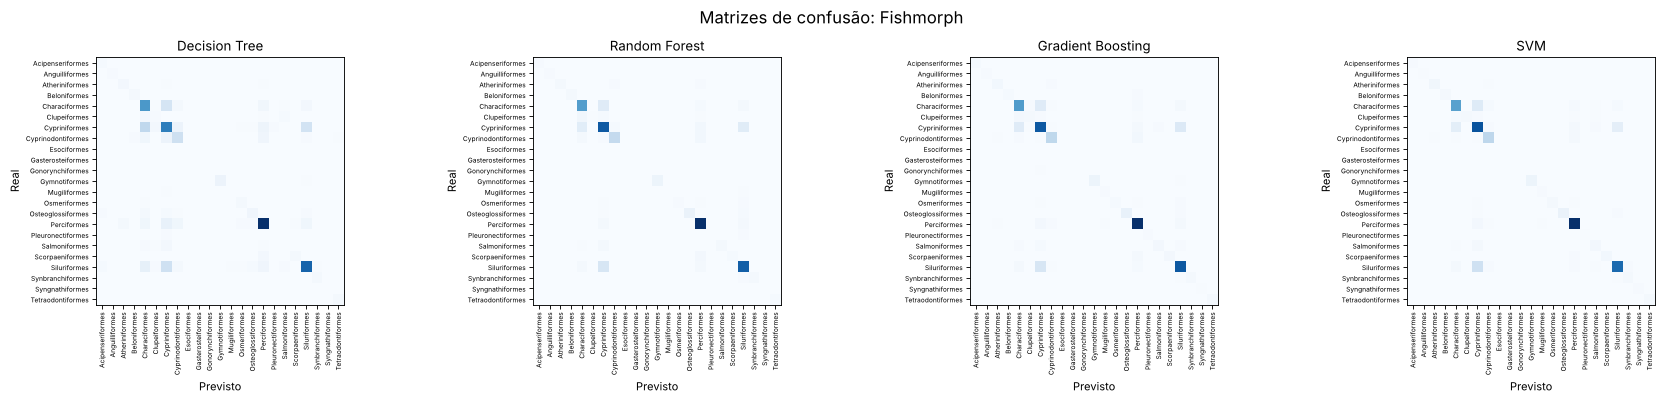

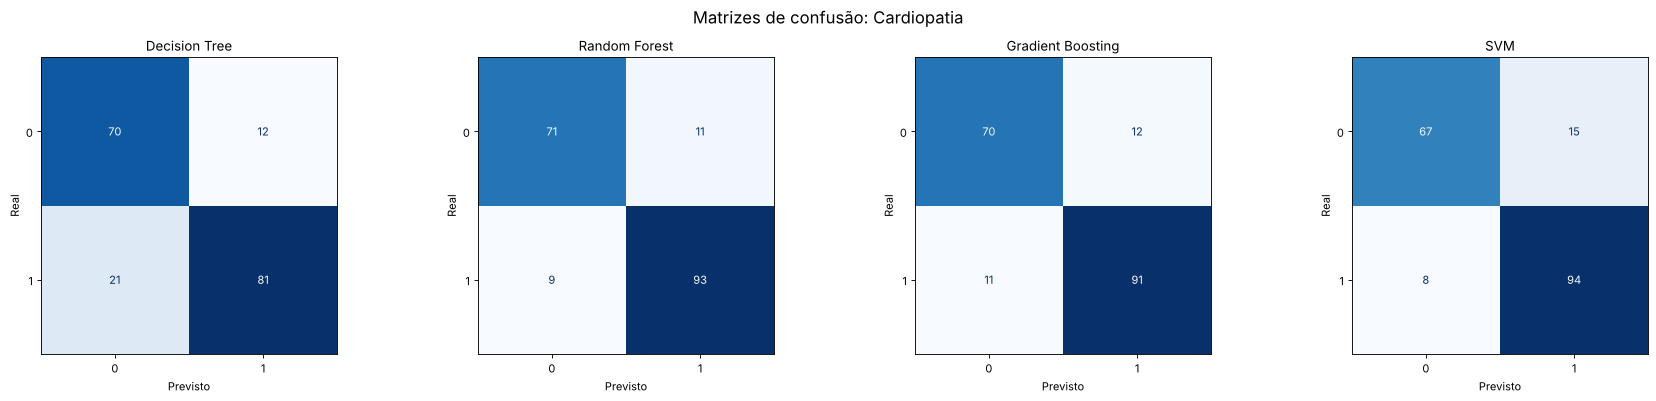

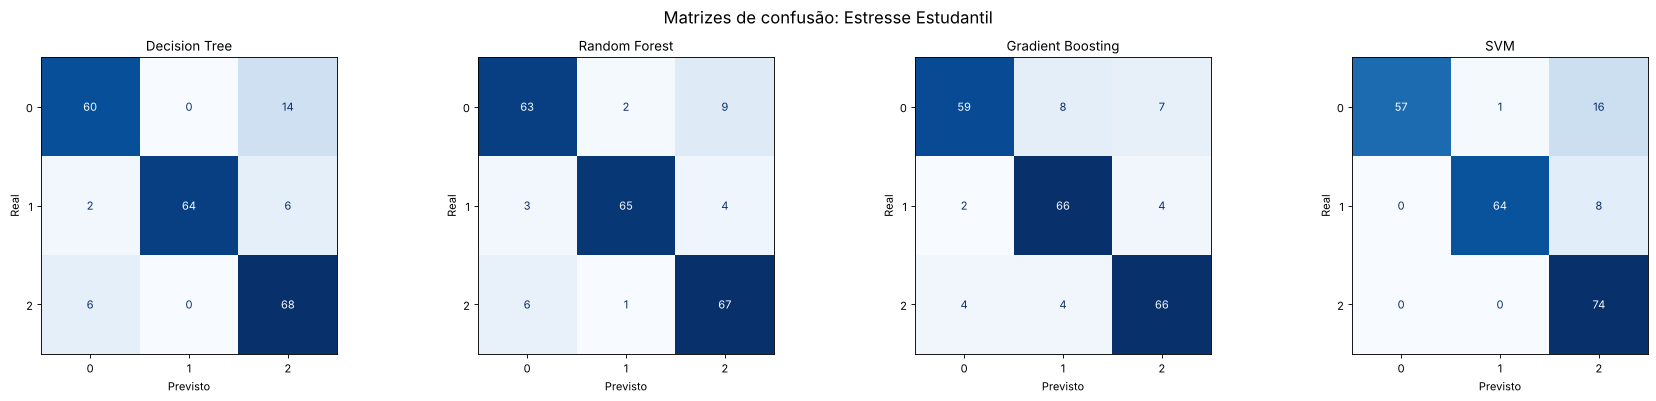

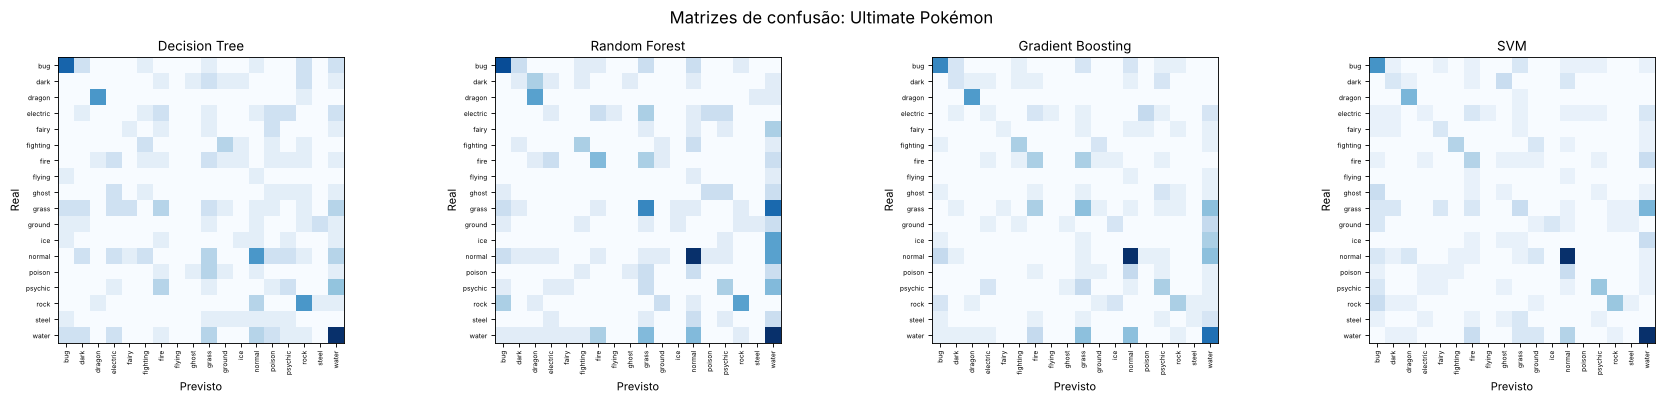

In [7]:
for nome_ds in datasets:
    fig, eixos = plt.subplots(1, 4, figsize=(22, 5))
    for eixo, nome_modelo in zip(eixos, modelos):
        y_test, y_pred, _, classes = previsoes[(nome_ds, nome_modelo)]
        muitas_classes = len(classes) > 10
        ConfusionMatrixDisplay.from_predictions(
            y_test, y_pred, labels=classes, ax=eixo, cmap="Blues", colorbar=False,
            include_values=not muitas_classes, xticks_rotation="vertical" if muitas_classes else "horizontal")
        eixo.set_title(nome_modelo)
        eixo.set_xlabel("Previsto")
        eixo.set_ylabel("Real")
        if muitas_classes:
            eixo.tick_params(labelsize=6)
    fig.suptitle(f"Matrizes de confusão: {nome_ds}", fontsize=15)
    plt.tight_layout()
    plt.savefig(f"resultados/figuras/confusao_{nome_ds}.png", dpi=120, bbox_inches="tight")
    plt.show()

## 7. Curvas ROC

Quanto mais a curva se aproxima do canto superior esquerdo, melhor; a linha tracejada é um classificador aleatório.
Nos datasets com mais de 2 classes, a curva junta todas as classes ("um contra todos").

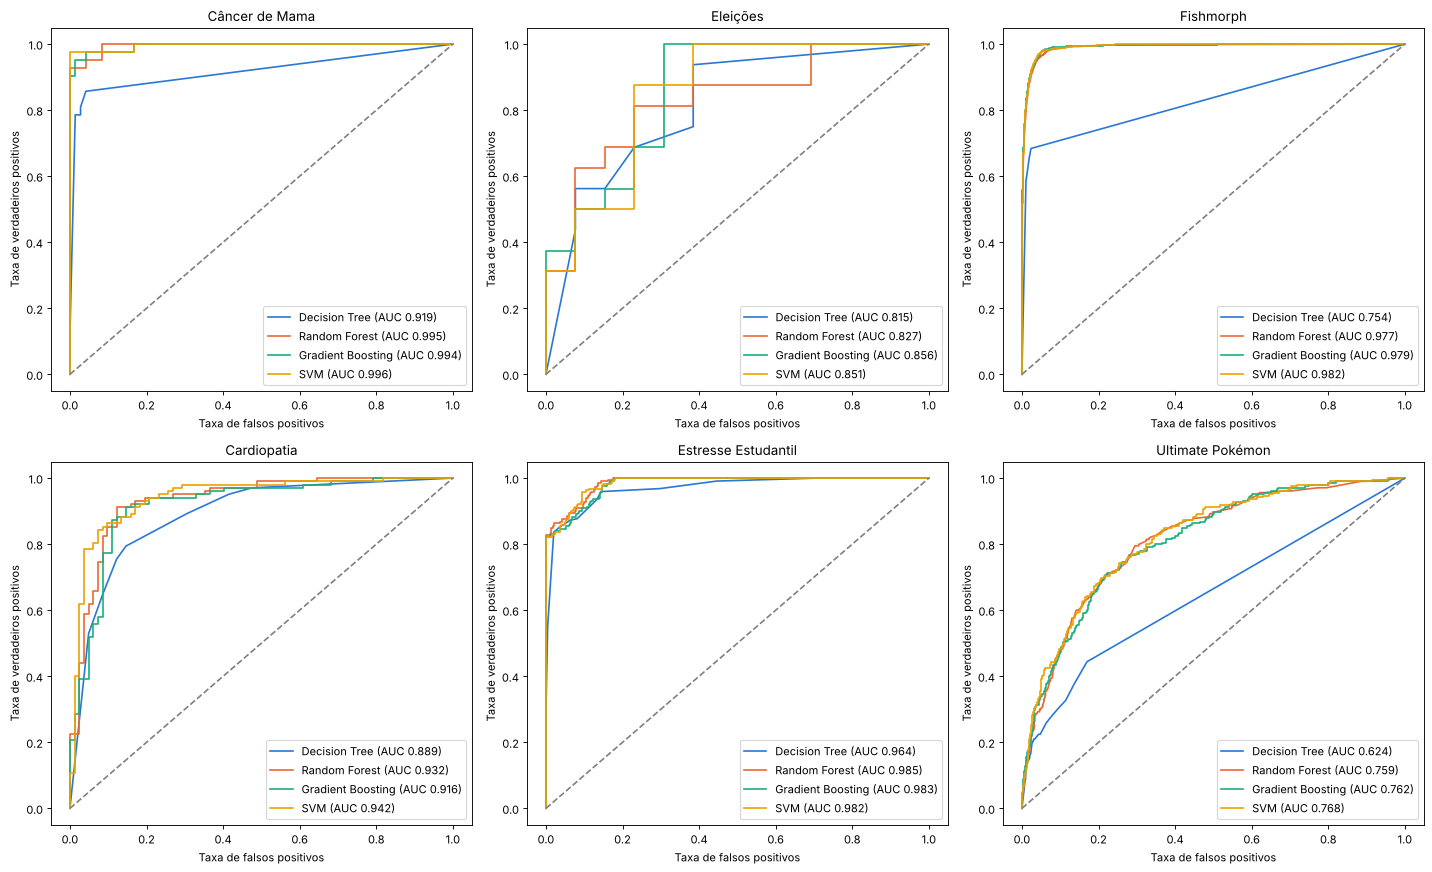

In [8]:
cores = {"Decision Tree": "#2a78d6", "Random Forest": "#eb6834", "Gradient Boosting": "#1baf7a", "SVM": "#eda100"}

fig, eixos = plt.subplots(2, 3, figsize=(18, 11))
for eixo, nome_ds in zip(eixos.ravel(), datasets):
    for nome_modelo in modelos:
        y_test, _, probabilidades, classes = previsoes[(nome_ds, nome_modelo)]
        if len(classes) == 2:
            fpr, tpr, _ = roc_curve(y_test == classes[1], probabilidades[:, 1])
        else:
            y_bin = label_binarize(y_test, classes=classes)
            fpr, tpr, _ = roc_curve(y_bin.ravel(), probabilidades.ravel())
        auc = tabela[(tabela["Dataset"] == nome_ds) & (tabela["Modelo"] == nome_modelo)]["ROC AUC"].iloc[0]
        eixo.plot(fpr, tpr, color=cores[nome_modelo], label=f"{nome_modelo} (AUC {auc:.3f})")
    eixo.plot([0, 1], [0, 1], "--", color="gray")
    eixo.set_title(nome_ds)
    eixo.set_xlabel("Taxa de falsos positivos")
    eixo.set_ylabel("Taxa de verdadeiros positivos")
    eixo.legend(loc="lower right")
plt.tight_layout()
plt.savefig("resultados/figuras/curvas_roc.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Viés e variância: Random Forest ou Gradient Boosting?

Comparamos o F1 no **treino** com o F1 na **validação** (média dos folds da validação cruzada):

- **Alta variância (overfitting):** o modelo vai muito melhor no treino que na validação, com diferença (gap) maior que 0,10. Ele decorou o treino.
- **Alto viés (underfitting):** o modelo vai mal até no treino (F1 de treino abaixo de 0,80). Ele é simples demais para o problema.

Isso ajuda a escolher entre os dois ensembles de árvores:

- **Random Forest** (bagging) tira a média de muitas árvores profundas, o que **reduz a variância**.
- **Gradient Boosting** (boosting) soma árvores pequenas em sequência, cada uma corrigindo o erro da anterior, o que **reduz o viés**.

In [9]:
def diagnostico(f1_treino, f1_validacao):
    gap = f1_treino - f1_validacao
    if gap > 0.10:
        return "Alta variância (overfitting)"
    if f1_treino < 0.80:
        return "Alto viés (underfitting)"
    return "Equilibrado"


tabela["Gap"] = tabela["F1 treino (CV)"] - tabela["F1 validação (CV)"]
tabela["Diagnóstico"] = [diagnostico(t, v) for t, v in zip(tabela["F1 treino (CV)"], tabela["F1 validação (CV)"])]
tabela.to_csv("resultados/metricas.csv", index=False)

colunas = ["Dataset", "Modelo", "F1 treino (CV)", "F1 validação (CV)", "Gap", "Diagnóstico"]
display(tabela[colunas].style.format({"F1 treino (CV)": "{:.3f}", "F1 validação (CV)": "{:.3f}", "Gap": "{:.3f}"}))

,Dataset,Modelo,F1 treino (CV),F1 validação (CV),Gap,Diagnóstico
0,Câncer de Mama,Decision Tree,0.960,0.924,0.036,Equilibrado
1,Câncer de Mama,Random Forest,0.993,0.965,0.028,Equilibrado
2,Câncer de Mama,Gradient Boosting,1.000,0.964,0.036,Equilibrado
3,Câncer de Mama,SVM,0.985,0.974,0.011,Equilibrado
4,Eleições,Decision Tree,0.911,0.842,0.069,Equilibrado
5,Eleições,Random Forest,1.000,0.803,0.197,Alta variância (overfitting)
6,Eleições,Gradient Boosting,0.976,0.797,0.179,Alta variância (overfitting)
7,Eleições,SVM,0.862,0.804,0.058,Equilibrado
8,Fishmorph,Decision Tree,0.805,0.426,0.379,Alta variância (overfitting)
9,Fishmorph,Random Forest,0.999,0.583,0.416,Alta variância (overfitting)


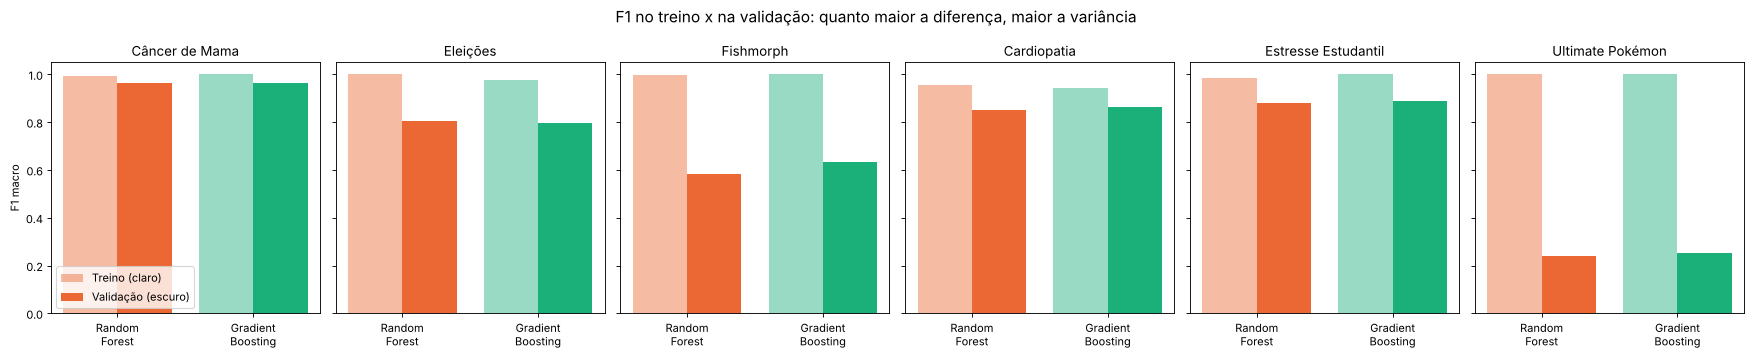

In [10]:
# Gráfico: F1 de treino x F1 de validação do Random Forest e do Gradient Boosting em cada dataset
fig, eixos = plt.subplots(1, 6, figsize=(22, 4.5), sharey=True)
for eixo, nome_ds in zip(eixos, datasets):
    parte = tabela[(tabela["Dataset"] == nome_ds) & tabela["Modelo"].isin(["Random Forest", "Gradient Boosting"])]
    x = np.arange(2)
    eixo.bar(x - 0.2, parte["F1 treino (CV)"], 0.4, label="Treino", color=[cores[m] for m in parte["Modelo"]], alpha=0.45)
    eixo.bar(x + 0.2, parte["F1 validação (CV)"], 0.4, label="Validação", color=[cores[m] for m in parte["Modelo"]])
    eixo.set_xticks(x, ["Random\nForest", "Gradient\nBoosting"])
    eixo.set_title(nome_ds)
    eixo.set_ylim(0, 1.05)
eixos[0].set_ylabel("F1 macro")
eixos[0].legend(["Treino (claro)", "Validação (escuro)"], loc="lower left")
fig.suptitle("F1 no treino x na validação: quanto maior a diferença, maior a variância", fontsize=14)
plt.tight_layout()
plt.savefig("resultados/figuras/treino_x_validacao.png", dpi=120, bbox_inches="tight")
plt.show()

In [11]:
escolhas = []
for nome_ds in datasets:
    rf = tabela[(tabela["Dataset"] == nome_ds) & (tabela["Modelo"] == "Random Forest")].iloc[0]
    gb = tabela[(tabela["Dataset"] == nome_ds) & (tabela["Modelo"] == "Gradient Boosting")].iloc[0]

    # 1) Qual é o problema do dataset? Olhamos os dois ensembles.
    if rf["Gap"] > 0.10 and gb["Gap"] > 0.10:
        problema = "alta variância"
        teoria = "Random Forest"
    elif rf["F1 treino (CV)"] < 0.80 and gb["F1 treino (CV)"] < 0.80:
        problema = "alto viés"
        teoria = "Gradient Boosting"
    else:
        problema = "sem problema dominante"
        teoria = None

    # 2) Quem generalizou melhor? Se a diferença for muito pequena (< 0,02), é empate,
    #    e escolhemos o de menor gap, isto é, o que perde menos do treino para a validação.
    diferenca = rf["F1 validação (CV)"] - gb["F1 validação (CV)"]
    if abs(diferenca) < 0.02:
        escolha = "Random Forest" if rf["Gap"] < gb["Gap"] else "Gradient Boosting"
        motivo = f"empate na validação (diferença de {abs(diferenca):.3f}); vence o de menor gap"
    else:
        escolha = "Random Forest" if diferenca > 0 else "Gradient Boosting"
        motivo = f"maior F1 na validação (diferença de {abs(diferenca):.3f})"

    texto = (f"{nome_ds}: {problema} (gap RF = {rf['Gap']:.3f}, gap GB = {gb['Gap']:.3f}). "
             f"Escolha: {escolha}, por {motivo}.")
    if teoria and teoria == escolha:
        texto += f" Confirma a teoria: {problema} pede {teoria}."
    elif teoria:
        texto += f" Contraria a teoria ({problema} pediria {teoria}): aqui o {escolha} controlou melhor o problema."
    print(texto, "\n")
    escolhas.append({"Dataset": nome_ds, "Problema": problema, "Gap RF": rf["Gap"], "Gap GB": gb["Gap"],
                     "F1 validação RF": rf["F1 validação (CV)"], "F1 validação GB": gb["F1 validação (CV)"],
                     "Escolha": escolha, "Motivo": motivo})

pd.DataFrame(escolhas).to_csv("resultados/escolha_rf_gb.csv", index=False)

Câncer de Mama: sem problema dominante (gap RF = 0.028, gap GB = 0.036). Escolha: Random Forest, por empate na validação (diferença de 0.000); vence o de menor gap. 

Eleições: alta variância (gap RF = 0.197, gap GB = 0.179). Escolha: Gradient Boosting, por empate na validação (diferença de 0.006); vence o de menor gap. Contraria a teoria (alta variância pediria Random Forest): aqui o Gradient Boosting controlou melhor o problema. 

Fishmorph: alta variância (gap RF = 0.416, gap GB = 0.367). Escolha: Gradient Boosting, por maior F1 na validação (diferença de 0.050). Contraria a teoria (alta variância pediria Random Forest): aqui o Gradient Boosting controlou melhor o problema. 

Cardiopatia: sem problema dominante (gap RF = 0.101, gap GB = 0.081). Escolha: Gradient Boosting, por empate na validação (diferença de 0.009); vence o de menor gap. 

Estresse Estudantil: alta variância (gap RF = 0.105, gap GB = 0.112). Escolha: Random Forest, por empate na validação (diferença de 0.009); venc

## 9. Conclusão

- As tabelas da seção 5 mostram o melhor modelo de cada dataset no teste.
- A seção 8 mostra, para cada dataset, se o problema é de variância ou de viés e qual ensemble foi escolhido, e por quê.
- Tudo foi salvo na pasta `resultados/`: `metricas.csv`, `escolha_rf_gb.csv` e os gráficos em `resultados/figuras/`.